# CareerPilot AI — Phase 3F-2: Career Roadmap ML Engine Development

## 1. Project Overview & Research Objective
The Career Roadmap engine generates personalized, prerequisite-ordered learning paths across six canonical roles (`Frontend Developer`, `Backend Developer`, `Python Developer`, `Data Analyst`, `Data Scientist`, `Machine Learning Engineer`) using:
- **Semantic matching (`all-MiniLM-L6-v2`)** for informal role and skill strings.
- **Knowledge-based Prerequisite DAG + Kahn's Topological Sort** for deterministic learning order.
- **Progress-aware filtering** that excludes completed/known skills and maps only verified official documentation.

**Disclaimer:** Provides learning-path guidance only — not employment predictions, guaranteed career outcomes, or verified proficiency certificates.


## 2. Dataset Creation & Inspection
We load the **26 curated PII-free development/test scenarios** (`datasets/benchmark_cases.json`).


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from career_roadmap import (
    CareerRoadmapEngine,
    SKILL_TAXONOMY,
    ROLE_REQUIREMENTS,
    validate_prerequisite_graph,
)
from evaluate_career_roadmap import (
    load_benchmark_cases,
    compare_minilm_vs_tfidf,
    run_evaluation,
)

# Project Pastel Palette
PASTEL_LAVENDER = "#A78BCE"
PASTEL_BLUE = "#7FB3D5"
PASTEL_GREEN = "#7CC49B"
PASTEL_PINK = "#E295B0"
CHARCOAL = "#262233"

plt.rcParams["figure.facecolor"] = "#FFFFFF"
plt.rcParams["axes.facecolor"] = "#FBF9FF"
plt.rcParams["axes.edgecolor"] = "#D5C9E8"
plt.rcParams["text.color"] = CHARCOAL
plt.rcParams["axes.labelcolor"] = CHARCOAL
plt.rcParams["xtick.color"] = CHARCOAL
plt.rcParams["ytick.color"] = CHARCOAL

cases = load_benchmark_cases()
print(f"Loaded {len(cases)} curated benchmark cases.")
print(f"Supported roles ({len(ROLE_REQUIREMENTS)}): {list(ROLE_REQUIREMENTS.keys())}")
print(f"Canonical skills in taxonomy: {len(SKILL_TAXONOMY)}")


Loaded 26 curated benchmark cases.
Supported roles (6): ['Frontend Developer', 'Backend Developer', 'Python Developer', 'Data Analyst', 'Data Scientist', 'Machine Learning Engineer']
Canonical skills in taxonomy: 22


## 3. Role Normalization & Semantic Matching + 4. Skill Taxonomy Construction
We inspect local offline model loading (`models/all-MiniLM-L6-v2`), role resolution with ambiguity detection, and skill alias disambiguation.


In [2]:
engine = CareerRoadmapEngine()
print("Local model source:", engine.model_source)

for raw_role in ["Junior Data Science Grad", "ML Eng", "Frontend React Developer", "Software Programmer", "Head Pastry Chef"]:
    res = engine.resolve_role(raw_role)
    print(f"Role '{raw_role}' -> status={res['status']}, canonical={res['canonical_role']}, conf={res['confidence']}")


Local model source: D:\CareerPilot AI\ml\CareerRoadmap\models\all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Role 'Junior Data Science Grad' -> status=resolved, canonical=Data Scientist, conf=0.5471
Role 'ML Eng' -> status=resolved, canonical=Machine Learning Engineer, conf=1.0
Role 'Frontend React Developer' -> status=resolved, canonical=Frontend Developer, conf=0.6855
Role 'Software Programmer' -> status=ambiguous, canonical=None, conf=0.4197
Role 'Head Pastry Chef' -> status=unsupported, canonical=None, conf=0.1262


## 5. Alias Normalization & 6. TF-IDF Baseline Comparison
We compare `all-MiniLM-L6-v2` against a `TF-IDF` lexical baseline on informal role names and paraphrased skill phrases.


{
  "MiniLM (all-MiniLM-L6-v2)": {
    "role_accuracy": 1.0,
    "role_hits": "6/6",
    "skill_accuracy": 1.0,
    "skill_hits": "5/5",
    "avg_ms_per_query": 14.81
  },
  "TF-IDF Baseline": {
    "role_accuracy": 0.5,
    "role_hits": "3/6",
    "skill_accuracy": 1.0,
    "skill_hits": "5/5",
    "avg_ms_per_query": 16.41
  }
}


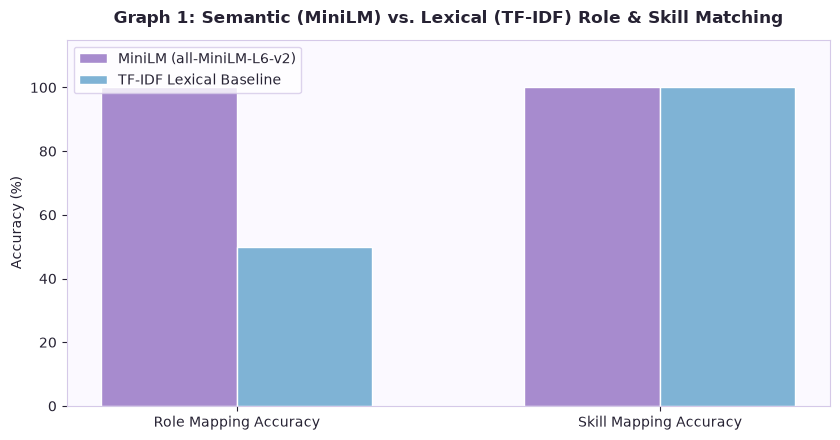

In [3]:
comp = compare_minilm_vs_tfidf(engine)
print(json.dumps(comp, indent=2))

# Graph 1: Semantic vs. Lexical Matching (Pastel Palette)
metrics = ["Role Mapping Accuracy", "Skill Mapping Accuracy"]
minilm_scores = [comp["MiniLM (all-MiniLM-L6-v2)"]["role_accuracy"] * 100, comp["MiniLM (all-MiniLM-L6-v2)"]["skill_accuracy"] * 100]
tfidf_scores = [comp["TF-IDF Baseline"]["role_accuracy"] * 100, comp["TF-IDF Baseline"]["skill_accuracy"] * 100]

x = np.arange(len(metrics))
w = 0.32
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.bar(x - w/2, minilm_scores, w, label="MiniLM (all-MiniLM-L6-v2)", color=PASTEL_LAVENDER, edgecolor="#FFFFFF")
ax.bar(x + w/2, tfidf_scores, w, label="TF-IDF Lexical Baseline", color=PASTEL_BLUE, edgecolor="#FFFFFF")
ax.set_title("Graph 1: Semantic (MiniLM) vs. Lexical (TF-IDF) Role & Skill Matching", fontweight="bold", pad=12)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 115)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8")
plt.tight_layout()
plt.show()


## 7. Prerequisite DAG Construction & Validation + 8. Topological Sequencing
We validate that the production prerequisite graph has zero cycles and zero nonexistent skill references, then visualize the staged learning sequence (`foundational` → `intermediate` → `advanced`).


Prerequisite DAG valid: True (error=None)


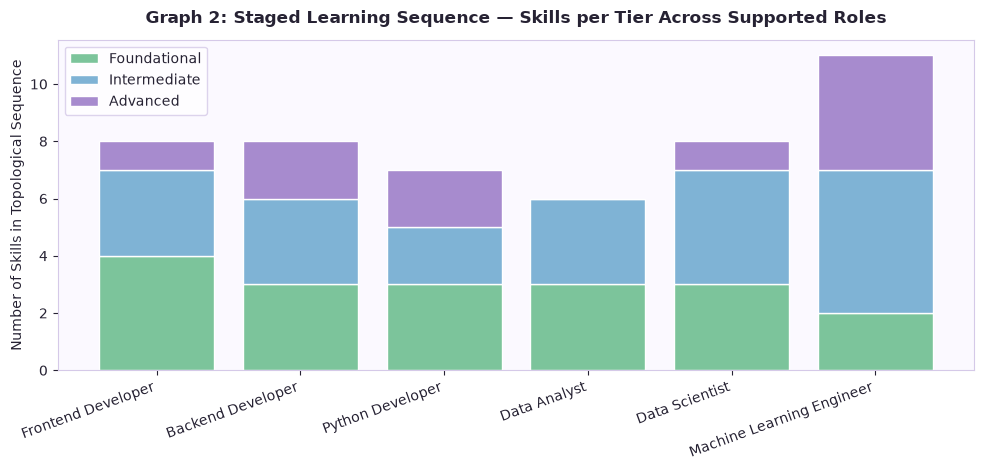

In [4]:
ok, err = validate_prerequisite_graph(SKILL_TAXONOMY, ROLE_REQUIREMENTS)
print(f"Prerequisite DAG valid: {ok} (error={err})")

# Graph 2: Prerequisite Learning Sequence (Skills by Tier & Dependency Depth)
roles_list = list(ROLE_REQUIREMENTS.keys())
tiers = ["foundational", "intermediate", "advanced"]
tier_colors = [PASTEL_GREEN, PASTEL_BLUE, PASTEL_LAVENDER]

tier_counts = {t: [] for t in tiers}
for r in roles_list:
    r_skills = ROLE_REQUIREMENTS[r]["required_skill_ids"]
    for t in tiers:
        tier_counts[t].append(sum(1 for sid in r_skills if SKILL_TAXONOMY[sid]["tier"] == t))

fig, ax = plt.subplots(figsize=(10, 4.8))
bottom = np.zeros(len(roles_list))
for t, col in zip(tiers, tier_colors):
    vals = np.array(tier_counts[t])
    ax.bar(roles_list, vals, bottom=bottom, label=t.title(), color=col, edgecolor="#FFFFFF")
    bottom += vals

ax.set_title("Graph 2: Staged Learning Sequence — Skills per Tier Across Supported Roles", fontweight="bold", pad=12)
ax.set_ylabel("Number of Skills in Topological Sequence")
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## 9. Progress-Aware Roadmap Generation & Coverage Analysis
We simulate a representative learner profile (`Python`, `SQL`, `Git`, `HTML5`) across all 6 supported roles to inspect **Known/Completed** vs. **Missing Actionable** vs. **Blocked-by-Prerequisite** skills.


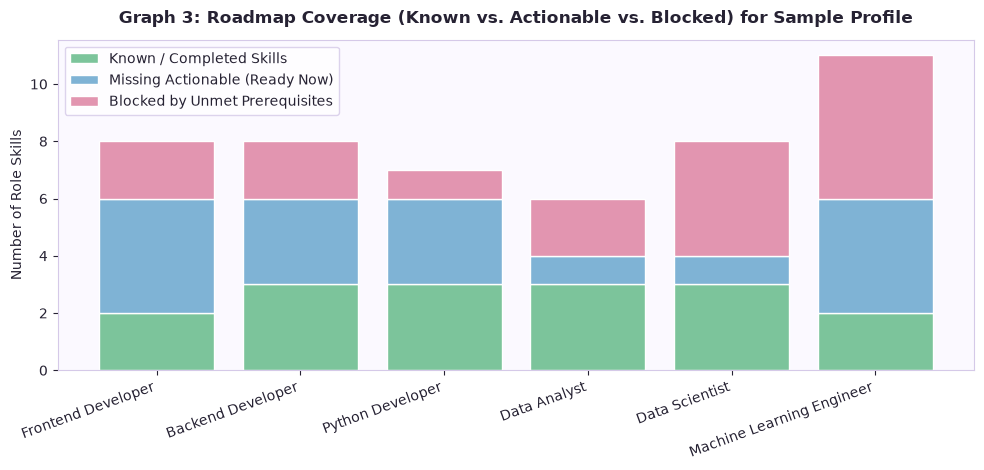

In [5]:
sample_known = ["Python", "SQL", "Git", "HTML5"]
known_counts, actionable_counts, blocked_counts = [], [], []

for r in roles_list:
    rm = engine.generate_roadmap(target_role=r, known_skills=sample_known)
    known_counts.append(rm["current_skill_assessment"]["satisfied_count"])
    actionable_counts.append(len(rm["recommended_next_skills"]))
    blocked_counts.append(len(rm["blocked_skills"]))

# Graph 3: Roadmap Recommendation Coverage
fig, ax = plt.subplots(figsize=(10, 4.8))
k_arr = np.array(known_counts)
a_arr = np.array(actionable_counts)
b_arr = np.array(blocked_counts)

ax.bar(roles_list, k_arr, label="Known / Completed Skills", color=PASTEL_GREEN, edgecolor="#FFFFFF")
ax.bar(roles_list, a_arr, bottom=k_arr, label="Missing Actionable (Ready Now)", color=PASTEL_BLUE, edgecolor="#FFFFFF")
ax.bar(roles_list, b_arr, bottom=k_arr+a_arr, label="Blocked by Unmet Prerequisites", color=PASTEL_PINK, edgecolor="#FFFFFF")

ax.set_title("Graph 3: Roadmap Coverage (Known vs. Actionable vs. Blocked) for Sample Profile", fontweight="bold", pad=12)
ax.set_ylabel("Number of Role Skills")
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## 10. Evaluation & Error Analysis + 11. Model Comparison + 12. Artifact Export
We run the complete 26-case evaluation suite (`run_evaluation()`) and verify all exported JSON artifacts.


In [6]:
full_eval = run_evaluation()
rep = full_eval["evaluation_report"]
print(f"Passed: {rep['passed']}/{rep['total_cases']} | Failed: {rep['failed']} | Runtime: {rep['runtime_seconds']}s")
print("Exported artifacts:", [p.name for p in sorted(Path("artifacts").glob("*.json"))])


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Passed: 26/26 | Failed: 0 | Runtime: 1.049s
Exported artifacts: ['evaluation_report.json', 'model_comparison.json', 'prerequisite_graph.json', 'roadmap_config.json', 'role_requirements.json', 'skill_taxonomy.json']


## 13. Limitations & Conclusions
- Role and skill matching uses `all-MiniLM-L6-v2` semantic similarity paired with explicit boundary-safe aliases and a deterministic prerequisite DAG.
- Unknown user skills are preserved in `uncertain_skills` rather than silently discarded or fabricated.
- Scores and estimated study hours represent learning-path guidance only, not employment probability or verified proficiency.
